In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# load the csvs
twsa = pd.read_csv("/home/mgurazada/snowdroughts_thirst/data/twsa_boxplot_data.csv")
swsa = pd.read_csv("/home/mgurazada/snowdroughts_thirst/data/swsa_boxplot_data.csv")
# rsa  = pd.read_csv("/home/mgurazada/snowdroughts_thirst/data/rsa_boxplot_data.csv")

# df = pd.concat([twsa, swsa, rsa], ignore_index=True)
df = pd.concat([twsa, swsa], ignore_index=True)

df.head()

,MAIN_BAS,group,delta_mm,variable
0,1040029430,normal,-0.655796,twsa
1,1040029430,low_swe_only,11.394677,twsa
2,1040029430,high_eto_only,5.642370,twsa
3,1040029430,low_swe_high_eto,-16.570391,twsa
4,1040029700,normal,16.099054,twsa


In [3]:
# ------------------------------------------------------------
# Create compound-minus-comparison differences from raw boxplot data
# ------------------------------------------------------------

# Keep only the groups needed
keep_groups = [
    "low_swe_high_eto",
    "low_swe_only",
    "high_eto_only",
    "normal"
]

df = df[df["group"].isin(keep_groups)].copy()

# Wide format: one row per basin and variable
df_wide = (
    df.pivot_table(
        index=["MAIN_BAS", "variable"],
        columns="group",
        values="delta_mm",
        aggfunc="mean"
    )
    .reset_index()
)

# Calculate paired basin-level differences
df_wide["comp_minus_normal"] = (
    df_wide["low_swe_high_eto"] - df_wide["normal"]
)

df_wide["comp_minus_snow_only"] = (
    df_wide["low_swe_high_eto"] - df_wide["low_swe_only"]
)

df_wide["comp_minus_demand_only"] = (
    df_wide["low_swe_high_eto"] - df_wide["high_eto_only"]
)

# Convert back to long format for boxplot
df_diff = df_wide.melt(
    id_vars=["MAIN_BAS", "variable"],
    value_vars=[
        "comp_minus_normal",
        "comp_minus_snow_only",
        "comp_minus_demand_only"
    ],
    var_name="comparison",
    value_name="delta_mm"
)

comparison_map = {
    "comp_minus_normal": "Compound − Non-drought",
    "comp_minus_snow_only": "Compound − Snow drought only",
    "comp_minus_demand_only": "Compound − Demand drought only"
}

var_map = {
    "twsa": "TWS",
    "swsa": "SMA"
}

comparison_order = [
    "Compound − Non-drought",
    "Compound − Snow drought only",
    "Compound − Demand drought only"
]

var_order = ["TWS", "SMA"]

df_diff["comparison"] = df_diff["comparison"].map(comparison_map)
df_diff["variable"] = df_diff["variable"].map(var_map)

df_diff["comparison"] = pd.Categorical(
    df_diff["comparison"],
    categories=comparison_order,
    ordered=True
)

df_diff["variable"] = pd.Categorical(
    df_diff["variable"],
    categories=var_order,
    ordered=True
)

df_diff = df_diff.dropna(subset=["delta_mm", "comparison", "variable"]).copy()

df_diff.head()

,MAIN_BAS,variable,comparison,delta_mm
0,1040029430,SMA,Compound − Non-drought,-18.359803
1,1040029430,TWS,Compound − Non-drought,-15.914595
2,1040029700,SMA,Compound − Non-drought,-37.464852
3,1040029700,TWS,Compound − Non-drought,-57.200002
4,2040000010,SMA,Compound − Non-drought,-23.039072


In [4]:
# ------------------------------------------------------------
# Check data
# ------------------------------------------------------------
print(df_diff.head())
print(df_diff.groupby(["variable", "comparison"], observed=True)["delta_mm"].count())

     MAIN_BAS variable              comparison   delta_mm
0  1040029430      SMA  Compound − Non-drought -18.359803
1  1040029430      TWS  Compound − Non-drought -15.914595
2  1040029700      SMA  Compound − Non-drought -37.464852
3  1040029700      TWS  Compound − Non-drought -57.200002
4  2040000010      SMA  Compound − Non-drought -23.039072
variable  comparison                    
TWS       Compound − Non-drought            185
          Compound − Snow drought only      185
          Compound − Demand drought only    184
SMA       Compound − Non-drought            171
          Compound − Snow drought only      173
          Compound − Demand drought only    169
Name: delta_mm, dtype: int64


In [5]:
summary = (
    df_diff.groupby(["variable", "comparison"], observed=True)
    .agg(
        n=("delta_mm", "count"),
        mean=("delta_mm", "mean"),
        median=("delta_mm", "median"),
        q25=("delta_mm", lambda x: np.nanpercentile(x, 25)),
        q75=("delta_mm", lambda x: np.nanpercentile(x, 75)),
        pct_negative=("delta_mm", lambda x: 100 * np.mean(np.asarray(x) < 0)),
    )
    .reset_index()
)

summary

,variable,comparison,n,mean,median,q25,q75,pct_negative
0,TWS,Compound − Non-drought,185,-39.338499,-35.254493,-66.230805,-12.633356,89.189189
1,TWS,Compound − Snow drought only,185,-28.630515,-22.667794,-56.471045,-2.069352,78.378378
2,TWS,Compound − Demand drought only,184,-4.049764,-6.076440,-26.738049,18.917264,58.695652
3,SMA,Compound − Non-drought,171,-39.242745,-33.167630,-56.990334,-11.323404,87.719298
4,SMA,Compound − Snow drought only,173,-31.962479,-24.850687,-49.509515,-5.779101,81.502890
5,SMA,Compound − Demand drought only,169,-3.439692,-5.818704,-25.450935,13.820385,57.396450


Saved figure to: /home/mgurazada/snowdroughts_thirst/code/certain/Fig_6.png


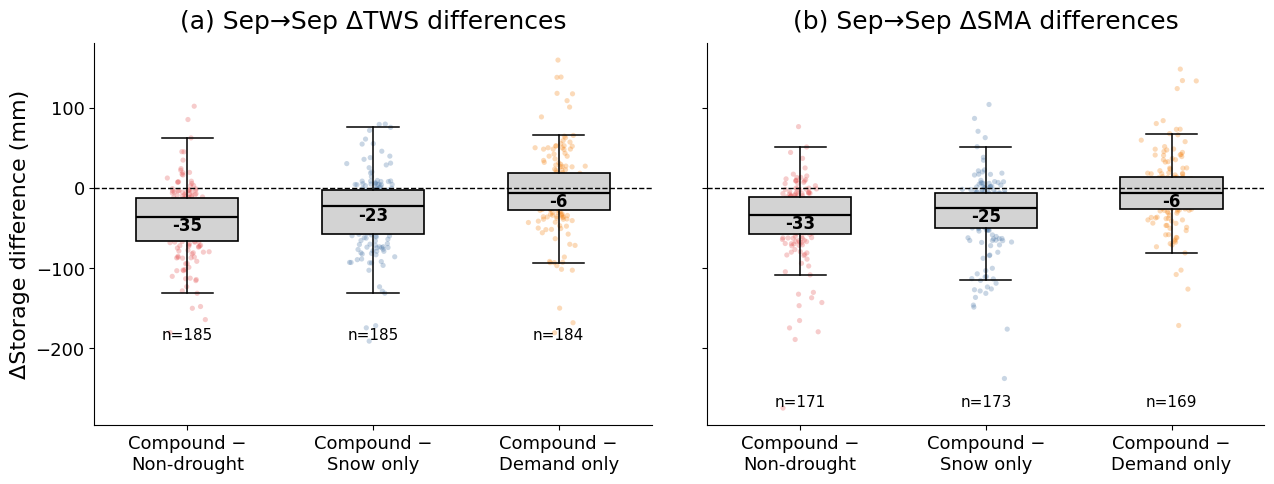

In [6]:
comparison_order = [
    "Compound − Non-drought",
    "Compound − Snow drought only",
    "Compound − Demand drought only"
]

def add_difference_boxplot(ax, data, title, ylabel=None):
    plot_data = [
        data.loc[data["comparison"] == comp, "delta_mm"].dropna().values
        for comp in comparison_order
    ]

    positions = np.arange(1, len(comparison_order) + 1)

    bp = ax.boxplot(
        plot_data,
        positions=positions,
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.6},
        boxprops={"linewidth": 1.2, "edgecolor": "black"},
        whiskerprops={"linewidth": 1.1, "color": "black"},
        capprops={"linewidth": 1.1, "color": "black"},
    )

    for patch in bp["boxes"]:
        patch.set_facecolor("lightgray")

    rng = np.random.default_rng(42)
    point_colors = ["#E45756", "#4C78A8", "#F58518"]

    for x, vals, c in zip(positions, plot_data, point_colors):
        if len(vals) == 0:
            continue

        jitter = rng.normal(0, 0.055, size=len(vals))

        ax.scatter(
            np.full(len(vals), x) + jitter,
            vals,
            s=14,
            alpha=0.30,
            edgecolor="none",
            color=c
        )

    ax.axhline(0, color="black", linewidth=1.0, linestyle="--")

    ax.set_xticks(positions)
    ax.set_xticklabels(
        [
            "Compound −\nNon-drought",
            "Compound −\nSnow only",
            "Compound −\nDemand only",
        ],
        fontsize=13
    )

    ax.set_title(title, fontsize=18, pad=10)

    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=16)

    ax.tick_params(axis="y", labelsize=13)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

    # median labels
    for x, vals in zip(positions, plot_data):
        if len(vals) == 0:
            continue

        med = np.nanmedian(vals)

        ax.text(
            x,
            med,
            f"{med:.0f}",
            ha="center",
            va="bottom" if med >= 0 else "top",
            fontsize=12,
            fontweight="bold"
        )

    # n labels near bottom
    ymin, ymax = ax.get_ylim()
    y_text = ymin + 0.04 * (ymax - ymin)

    for x, vals in zip(positions, plot_data):
        ax.text(
            x,
            y_text,
            f"n={len(vals)}",
            ha="center",
            va="bottom",
            fontsize=11
        )

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5.8),
    sharey=True
)

add_difference_boxplot(
    axes[0],
    df_diff[df_diff["variable"] == "TWS"],
    "(a) Sep→Sep ΔTWS differences",
    ylabel="ΔStorage difference (mm)"
)

add_difference_boxplot(
    axes[1],
    df_diff[df_diff["variable"] == "SMA"],
    "(b) Sep→Sep ΔSMA differences",
    ylabel=None
)

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.22,
    top=0.88,
    wspace=0.10
)

outpath = "/home/mgurazada/snowdroughts_thirst/code/certain/Fig_6.png"

fig.savefig(
    outpath,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print(f"Saved figure to: {outpath}")

plt.show()

In [7]:
comparison_order = [
    "Compound − Non-drought",
    "Compound − Snow drought only",
    "Compound − Demand drought only"
]

var_order = ["TWS", "SMA"]

df_diff["comparison"] = pd.Categorical(
    df_diff["comparison"],
    categories=comparison_order,
    ordered=True
)

df_diff["variable"] = pd.Categorical(
    df_diff["variable"],
    categories=var_order,
    ordered=True
)

In [8]:
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# ------------------------------------------------------------
# Test whether basin-level differences are significantly different from zero
# ------------------------------------------------------------

test_rows = []

for comp in comparison_order:
    for var in var_order:
        vals = df_diff.loc[
            (df_diff["comparison"] == comp) &
            (df_diff["variable"] == var),
            "delta_mm"
        ].dropna().values

        if len(vals) > 0:
            # Wilcoxon signed-rank test against zero
            # two-sided is safest
            stat, p = wilcoxon(
                vals,
                alternative="two-sided",
                zero_method="wilcox"
            )

            med = np.nanmedian(vals)
            q25 = np.nanpercentile(vals, 25)
            q75 = np.nanpercentile(vals, 75)
            pct_negative = 100 * np.mean(vals < 0)

        else:
            stat, p = np.nan, np.nan
            med, q25, q75, pct_negative = np.nan, np.nan, np.nan, np.nan

        test_rows.append({
            "comparison": comp,
            "variable": var,
            "n": len(vals),
            "median": med,
            "q25": q25,
            "q75": q75,
            "pct_negative": pct_negative,
            "wilcoxon_stat": stat,
            "p_value": p
        })

test_summary = pd.DataFrame(test_rows)

# Optional: FDR correction across the 6 tests
valid_p = test_summary["p_value"].notna()

test_summary.loc[valid_p, "p_fdr"] = multipletests(
    test_summary.loc[valid_p, "p_value"],
    method="fdr_bh"
)[1]

test_summary

,comparison,variable,n,median,q25,q75,pct_negative,wilcoxon_stat,p_value,p_fdr
0,Compound − Non-drought,TWS,185,-35.254493,-66.230805,-12.633356,89.189189,1261.0,7.801231e-24,4.680739e-23
1,Compound − Non-drought,SMA,171,-33.167630,-56.990334,-11.323404,87.719298,939.0,4.467263e-23,1.340179e-22
2,Compound − Snow drought only,TWS,185,-22.667794,-56.471045,-2.069352,78.378378,2686.0,4.969191e-16,7.453786e-16
3,Compound − Snow drought only,SMA,173,-24.850687,-49.509515,-5.779101,81.502890,1742.0,1.840516e-18,3.681032e-18
4,Compound − Demand drought only,TWS,184,-6.076440,-26.738049,18.917264,58.695652,7284.0,9.013582e-02,9.013582e-02
5,Compound − Demand drought only,SMA,169,-5.818704,-25.450935,13.820385,57.396450,6083.0,8.435285e-02,9.013582e-02


In [9]:
def p_to_stars(p):
    return "*" if np.isfinite(p) and p < 0.05 else ""

test_summary["stars"] = test_summary["p_value"].apply(p_to_stars)
test_summary["stars_fdr"] = test_summary["p_fdr"].apply(p_to_stars)

test_summary

,comparison,variable,n,median,q25,q75,pct_negative,wilcoxon_stat,p_value,p_fdr,stars,stars_fdr
0,Compound − Non-drought,TWS,185,-35.254493,-66.230805,-12.633356,89.189189,1261.0,7.801231e-24,4.680739e-23,*,*
1,Compound − Non-drought,SMA,171,-33.167630,-56.990334,-11.323404,87.719298,939.0,4.467263e-23,1.340179e-22,*,*
2,Compound − Snow drought only,TWS,185,-22.667794,-56.471045,-2.069352,78.378378,2686.0,4.969191e-16,7.453786e-16,*,*
3,Compound − Snow drought only,SMA,173,-24.850687,-49.509515,-5.779101,81.502890,1742.0,1.840516e-18,3.681032e-18,*,*
4,Compound − Demand drought only,TWS,184,-6.076440,-26.738049,18.917264,58.695652,7284.0,9.013582e-02,9.013582e-02,,
5,Compound − Demand drought only,SMA,169,-5.818704,-25.450935,13.820385,57.396450,6083.0,8.435285e-02,9.013582e-02,,


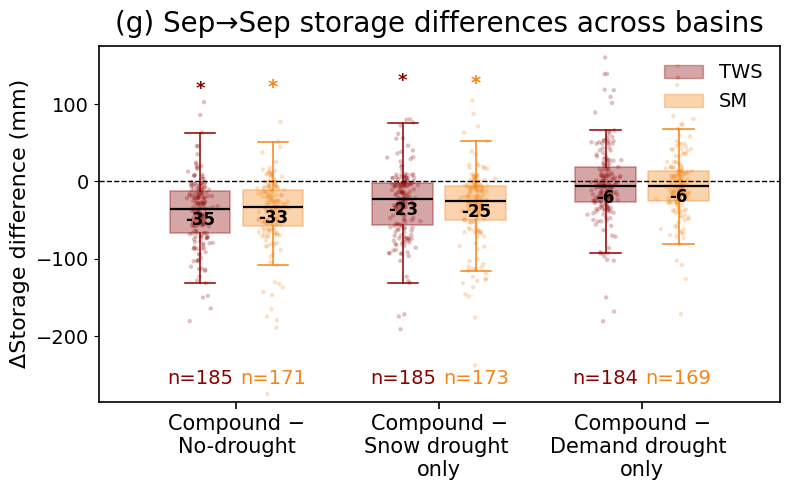

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# ------------------------------------------------------------
# Grouped boxplot: TWS and SMA side by side for each comparison
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

# x positions for the 3 comparison groups
group_centers = np.array([1, 2, 3])

# offsets so TWS and SMA appear side by side
offset = 0.18
pos_tws = group_centers - offset
pos_sma = group_centers + offset

width = 0.30

# colors
colors = {
    "TWS": "#8B0000",
    "SMA": "#F58518"
}

# comparison order
comparison_order = [
    "Compound − Non-drought",
    "Compound − Snow drought only",
    "Compound − Demand drought only"
]

# ------------------------------------------------------------
# Collect data
# ------------------------------------------------------------

tws_data = [
    df_diff.loc[
        (df_diff["comparison"] == comp) & (df_diff["variable"] == "TWS"),
        "delta_mm"
    ].dropna().values
    for comp in comparison_order
]

sma_data = [
    df_diff.loc[
        (df_diff["comparison"] == comp) & (df_diff["variable"] == "SMA"),
        "delta_mm"
    ].dropna().values
    for comp in comparison_order
]

# ------------------------------------------------------------
# Boxplots
# ------------------------------------------------------------

bp_tws = ax.boxplot(
    tws_data,
    positions=pos_tws,
    widths=width,
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "black", "linewidth": 1.6},
    boxprops={"linewidth": 1.2},
    whiskerprops={"linewidth": 1.1},
    capprops={"linewidth": 1.1},
)

bp_sma = ax.boxplot(
    sma_data,
    positions=pos_sma,
    widths=width,
    patch_artist=True,
    showfliers=False,
    medianprops={"color": "black", "linewidth": 1.6},
    boxprops={"linewidth": 1.2},
    whiskerprops={"linewidth": 1.1},
    capprops={"linewidth": 1.1},
)

# ------------------------------------------------------------
# Assign box colors
# ------------------------------------------------------------

for patch in bp_tws["boxes"]:
    patch.set_facecolor(colors["TWS"])
    patch.set_alpha(0.35)
    patch.set_edgecolor(colors["TWS"])

for patch in bp_sma["boxes"]:
    patch.set_facecolor(colors["SMA"])
    patch.set_alpha(0.35)
    patch.set_edgecolor(colors["SMA"])

# color whiskers and caps to match
for whisker in bp_tws["whiskers"]:
    whisker.set_color(colors["TWS"])

for cap in bp_tws["caps"]:
    cap.set_color(colors["TWS"])

for whisker in bp_sma["whiskers"]:
    whisker.set_color(colors["SMA"])

for cap in bp_sma["caps"]:
    cap.set_color(colors["SMA"])

# medians black
for median in bp_tws["medians"]:
    median.set_color("black")
    median.set_linewidth(1.6)

for median in bp_sma["medians"]:
    median.set_color("black")
    median.set_linewidth(1.6)

# ------------------------------------------------------------
# Jittered points
# ------------------------------------------------------------

rng = np.random.default_rng(42)

for x, vals in zip(pos_tws, tws_data):
    jitter = rng.normal(0, 0.03, size=len(vals))
    ax.scatter(
        np.full(len(vals), x) + jitter,
        vals,
        s=10,
        alpha=0.25,
        color=colors["TWS"],
        edgecolor="none"
    )

for x, vals in zip(pos_sma, sma_data):
    jitter = rng.normal(0, 0.03, size=len(vals))
    ax.scatter(
        np.full(len(vals), x) + jitter,
        vals,
        s=10,
        alpha=0.25,
        color=colors["SMA"],
        edgecolor="none"
    )

# ------------------------------------------------------------
# Median labels
# ------------------------------------------------------------

median_offset = 3  # mm; increase/decrease as needed

for x, vals in zip(pos_tws, tws_data):
    if len(vals) > 0:
        med = np.nanmedian(vals)
        ax.text(
            x,
            med - median_offset,
            f"{med:.0f}",
            ha="center",
            va="top",
            fontsize=12,
            fontweight="bold",
            color="black"
        )

for x, vals in zip(pos_sma, sma_data):
    if len(vals) > 0:
        med = np.nanmedian(vals)
        ax.text(
            x,
            med - median_offset,
            f"{med:.0f}",
            ha="center",
            va="top",
            fontsize=12,
            fontweight="bold",
            color="black"
        )

# ------------------------------------------------------------
# Add significance stars from Wilcoxon test
# ------------------------------------------------------------

star_y_offset = 120

for x, comp in zip(pos_tws, comparison_order):
    row = test_summary[
        (test_summary["comparison"] == comp) &
        (test_summary["variable"] == "TWS")
    ].iloc[0]

    vals = df_diff.loc[
        (df_diff["comparison"] == comp) &
        (df_diff["variable"] == "TWS"),
        "delta_mm"
    ].dropna().values

    if len(vals) > 0:
        y_star = np.nanpercentile(vals, 75) + star_y_offset

        ax.text(
            x,
            y_star,
            row["stars"],
            ha="center",
            va="bottom",
            fontsize=13,
            fontweight="bold",
            color=colors["TWS"]
        )

for x, comp in zip(pos_sma, comparison_order):
    row = test_summary[
        (test_summary["comparison"] == comp) &
        (test_summary["variable"] == "SMA")
    ].iloc[0]

    vals = df_diff.loc[
        (df_diff["comparison"] == comp) &
        (df_diff["variable"] == "SMA"),
        "delta_mm"
    ].dropna().values

    if len(vals) > 0:
        y_star = np.nanpercentile(vals, 75) + star_y_offset

        ax.text(
            x,
            y_star,
            row["stars"],
            ha="center",
            va="bottom",
            fontsize=14,
            fontweight="bold",
            color=colors["SMA"]
        )

        
# ------------------------------------------------------------
# n labels and tighter y-limits
# ------------------------------------------------------------

all_vals = np.concatenate(
    [v for v in tws_data + sma_data if len(v) > 0]
)

ymin_all = np.nanmin(all_vals)
ymax_all = np.nanmax(all_vals)

# Tighter y-limits to reduce white space
ax.set_ylim(ymin_all - 10, ymax_all + 15)

ymin, ymax = ax.get_ylim()
y_text = ymin + 0.04 * (ymax - ymin)

# Put TWS and SMA n labels on the same y-level
for x, vals in zip(pos_tws, tws_data):
    ax.text(
        x,
        y_text,
        f"n={len(vals)}",
        ha="center",
        va="bottom",
        fontsize=14,
        color=colors["TWS"]
    )

for x, vals in zip(pos_sma, sma_data):
    ax.text(
        x,
        y_text,
        f"n={len(vals)}",
        ha="center",
        va="bottom",
        fontsize=14,
        color=colors["SMA"]
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xticks(group_centers)

ax.set_xticklabels(
    [
        "Compound −\nNo-drought",
        "Compound −\nSnow drought \nonly",
        "Compound −\nDemand drought \nonly"
    ],
    fontsize=15
)

ax.set_ylabel(
    "ΔStorage difference (mm)",
    fontsize=16
)

ax.set_title(
    "(g) Sep→Sep storage differences across basins",
    fontsize=20,
    pad=10
)

ax.tick_params(
    axis="y",
    labelsize=14
)

ax.tick_params(
    axis="x",
    width=1.2,
    length=5,
    colors="black"
)

# Full black box around panel
for side in ["top", "bottom", "left", "right"]:
    ax.spines[side].set_visible(True)
    ax.spines[side].set_color("black")
    ax.spines[side].set_linewidth(1.2)

# ------------------------------------------------------------
# Legend
# ------------------------------------------------------------

legend_handles = [
    Patch(
        facecolor=colors["TWS"],
        edgecolor=colors["TWS"],
        alpha=0.35,
        label="TWS"
    ),
    Patch(
        facecolor=colors["SMA"],
        edgecolor=colors["SMA"],
        alpha=0.35,
        label="SM"
    ),
]

ax.legend(
    handles=legend_handles,
    frameon=False,
    fontsize=14,
    loc="upper right"
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

plt.tight_layout()

plt.savefig(
    "/home/mgurazada/snowdroughts_thirst/code/certain/Fig_6.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [11]:
abc

NameError: name 'abc' is not defined

In [ ]:
group_map = {
    "low_swe_high_eto": "Compound drought",
    "low_swe_only": "Snow drought only",
    "high_eto_only": "Demand drought only",
    "normal": "No drought"
}

var_map = {
    "twsa": "ΔTWS",
    "swsa": "ΔSMA"
}

group_order = [
    "Compound drought",
    "Snow drought only",
    "Demand drought only",
    "No drought"
]

var_order = ["twsa", "swsa"]

df["group_label"] = df["group"].map(group_map)
df["var_label"] = df["variable"].map(var_map)

df["variable"] = pd.Categorical(
    df["variable"],
    categories=var_order,
    ordered=True
)

df["group_label"] = pd.Categorical(
    df["group_label"],
    categories=group_order,
    ordered=True
)

df = df.dropna(subset=["group_label", "delta_mm", "variable"]).copy()

In [ ]:
# ------------------------------------------------------------
# Helper for boxplot panel
# ------------------------------------------------------------
def add_boxplot_panel(ax, data, title, ylabel=None):
    plot_data = [
        data.loc[data["group_label"] == g, "delta_mm"].dropna().values
        for g in group_order
    ]

    positions = np.arange(1, len(group_order) + 1)

    bp = ax.boxplot(
        plot_data,
        positions=positions,
        widths=0.55,
        patch_artist=True,
        showfliers=False,
        medianprops={"color": "black", "linewidth": 1.5},
        boxprops={"linewidth": 1.2},
        whiskerprops={"linewidth": 1.1},
        capprops={"linewidth": 1.1}
    )

    # light gray boxes
    for patch in bp["boxes"]:
        patch.set_facecolor("lightgray")
        patch.set_edgecolor("black")

    # jittered points
    rng = np.random.default_rng(42)

    for x, vals in zip(positions, plot_data):
        if len(vals) == 0:
            continue

        jitter = rng.normal(0, 0.055, size=len(vals))

        ax.scatter(
            np.full(len(vals), x) + jitter,
            vals,
            s=14,
            alpha=0.35,
            edgecolor="none"
        )

    ax.axhline(0, color="black", linewidth=1.0, linestyle="--")

    ax.set_xticks(positions)
    ax.set_xticklabels(group_order, fontsize=14)

    ax.set_title(title, fontsize=18, pad=10)

    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=16)

    ax.tick_params(axis="y", labelsize=14)

    for side in ["top", "right"]:
        ax.spines[side].set_visible(False)

    # add median labels
    for x, vals in zip(positions, plot_data):
        if len(vals) == 0:
            continue

        med = np.nanmedian(vals)

        ax.text(
            x,
            med,
            f"{med:.0f}",
            ha="center",
            va="bottom",
            fontsize=12,
            fontweight="bold"
        )

In [ ]:
# ------------------------------------------------------------
# Plot figure
# ------------------------------------------------------------
fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5.5),
    sharey=True
)

add_boxplot_panel(
    axes[0],
    df[df["variable"] == "twsa"],
    "(a) Sep→Sep ΔTWS by drought class",
    ylabel="Sep→Sep storage change (mm)"
)

add_boxplot_panel(
    axes[1],
    df[df["variable"] == "swsa"],
    "(b) Sep→Sep ΔSMA by drought class",
    ylabel=None
)

plt.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.18,
    top=0.90,
    wspace=0.10
)

outpath = "/home/mgurazada/snowdroughts_thirst/code/certain/Fig_6.png"

fig.savefig(
    outpath,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

print(f"Saved figure to: {outpath}")

plt.show()

In [ ]:
summary = (
    df.groupby(["variable", "group_label"], observed=True)
      .agg(
          n=("delta_mm", "count"),
          mean=("delta_mm", "mean"),
          median=("delta_mm", "median"),
          q25=("delta_mm", lambda x: np.nanpercentile(x, 25)),
          q75=("delta_mm", lambda x: np.nanpercentile(x, 75)),
          pct_negative=("delta_mm", lambda x: 100 * np.mean(np.asarray(x) < 0))
      )
      .reset_index()
)

summary

In [ ]:
# clean labels and set order

group_map = {
    "low_swe_high_eto": "Compound drought",
    "low_swe_only": "Snow drought only",
    "high_eto_only": "Demand drought only",
    "normal": "No drought"
}

# var_order = ["twsa", "swsa", "rsa"]
var_order = ["twsa", "swsa"]

group_order = ["compound droughts", "snow droughts", "demand droughts", "no-droughts"]

df["group_label"] = df["group"].map(group_map)
df["variable"] = pd.Categorical(df["variable"], categories=var_order, ordered=True)
df["group_label"] = pd.Categorical(df["group_label"], categories=group_order, ordered=True)

df = df.dropna(subset=["group_label", "delta_mm"])

In [ ]:
# make the grouped boxplot

fig, ax = plt.subplots(figsize=(10, 6))

group_positions = np.arange(len(group_order))

offsets = {
    "twsa": -0.25,
    "swsa":  0.00,
    "rsa":   0.25
}

width = 0.22

line_colors = {
    "twsa": "black",
    "swsa": "red",
    "rsa": "blue"
}

for var in var_order:
    data_list = []
    positions = []

    for i, grp in enumerate(group_order):
        vals = df.loc[
            (df["variable"] == var) & (df["group_label"] == grp),
            "delta_mm"
        ].dropna().values

        data_list.append(vals)
        positions.append(group_positions[i] + offsets[var])

    bp = ax.boxplot(
        data_list,
        positions=positions,
        widths=width,
        patch_artist=False,
        showfliers=False,
        medianprops=dict(color=line_colors[var], linewidth=1.5),
        boxprops=dict(color=line_colors[var], linewidth=1.5),
        whiskerprops=dict(color=line_colors[var], linewidth=1.2),
        capprops=dict(color=line_colors[var], linewidth=1.2)
    )

ax.axhline(0, color="gray", linestyle="-", linewidth=1)

ax.set_xticks(group_positions)
ax.set_xticklabels(group_order, fontsize=12)
ax.set_ylabel("Δ storage anomaly (mm)", fontsize=12)
ax.set_xlabel("")
ax.set_title("Basin-scale storage change", fontsize=14)

# custom legend
from matplotlib.lines import Line2D
legend_handles = [
    Line2D([0], [0], color="black", lw=2, label="twsa"),
    Line2D([0], [0], color="red", lw=2, label="swsa"),
    Line2D([0], [0], color="blue", lw=2, label="rsa"),
]
ax.legend(handles=legend_handles, frameon=True, loc="upper left")

plt.tight_layout()
plt.show()